<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/03_ehg_signal_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 03 - EHG Signal Preprocessing

## Project
Uterine EMG Analysis for Preterm Birth Detection

## Objective
To investigate and preprocess uterine EHG signals.

## Topics
1. Raw signal inspection
2. Noise and artifacts
3. Butterworth filters
4. Band-pass filtering
5. Forward-backward filtering
6. Raw vs filtered signal comparison
7. Signal quality inspection

In [1]:

# Install required library

!pip install -q wfdb PyWavelets


In [2]:

# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import butter, sosfiltfilt, welch

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# Load recording from PhysioNet

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

# Sampling frequency
fs = record.fs

# Extract S1 unfiltered signal
raw_signal = record.p_signal[:, 0]

print("Recording loaded!")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(raw_signal))
print("Duration:", len(raw_signal) / fs, "seconds")
print("Signal unit:", record.units[0])

Recording loaded!
Sampling frequency: 20 Hz
Number of samples: 35180
Duration: 1759.0 seconds
Signal unit: mV


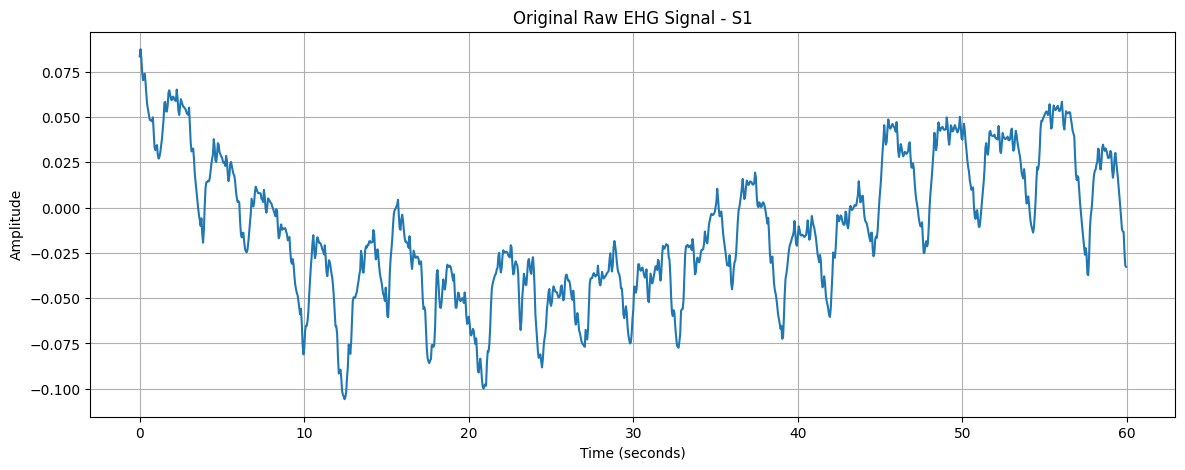

In [5]:

# Select the first 60 seconds

duration = 60

samples = duration * fs

time = np.arange(samples) / fs

plt.figure(figsize=(14, 5))

plt.plot(time, raw_signal[:samples])

plt.title("Original Raw EHG Signal - S1")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

In [6]:
# Design a Butterworth band-pass filter

low_cutoff = 0.08
high_cutoff = 4.0

filter_order = 4

sos = butter(
    filter_order,
    [low_cutoff, high_cutoff],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Butterworth filter designed successfully!")
print("Lower cutoff:", low_cutoff, "Hz")
print("Upper cutoff:", high_cutoff, "Hz")
print("Filter order:", filter_order)

Butterworth filter designed successfully!
Lower cutoff: 0.08 Hz
Upper cutoff: 4.0 Hz
Filter order: 4


In [7]:
# Apply forward-backward filtering

filtered_signal = sosfiltfilt(
    sos,
    raw_signal
)

print("Filtering completed!")

print("Original signal length:", len(raw_signal))

print("Filtered signal length:", len(filtered_signal))

Filtering completed!
Original signal length: 35180
Filtered signal length: 35180


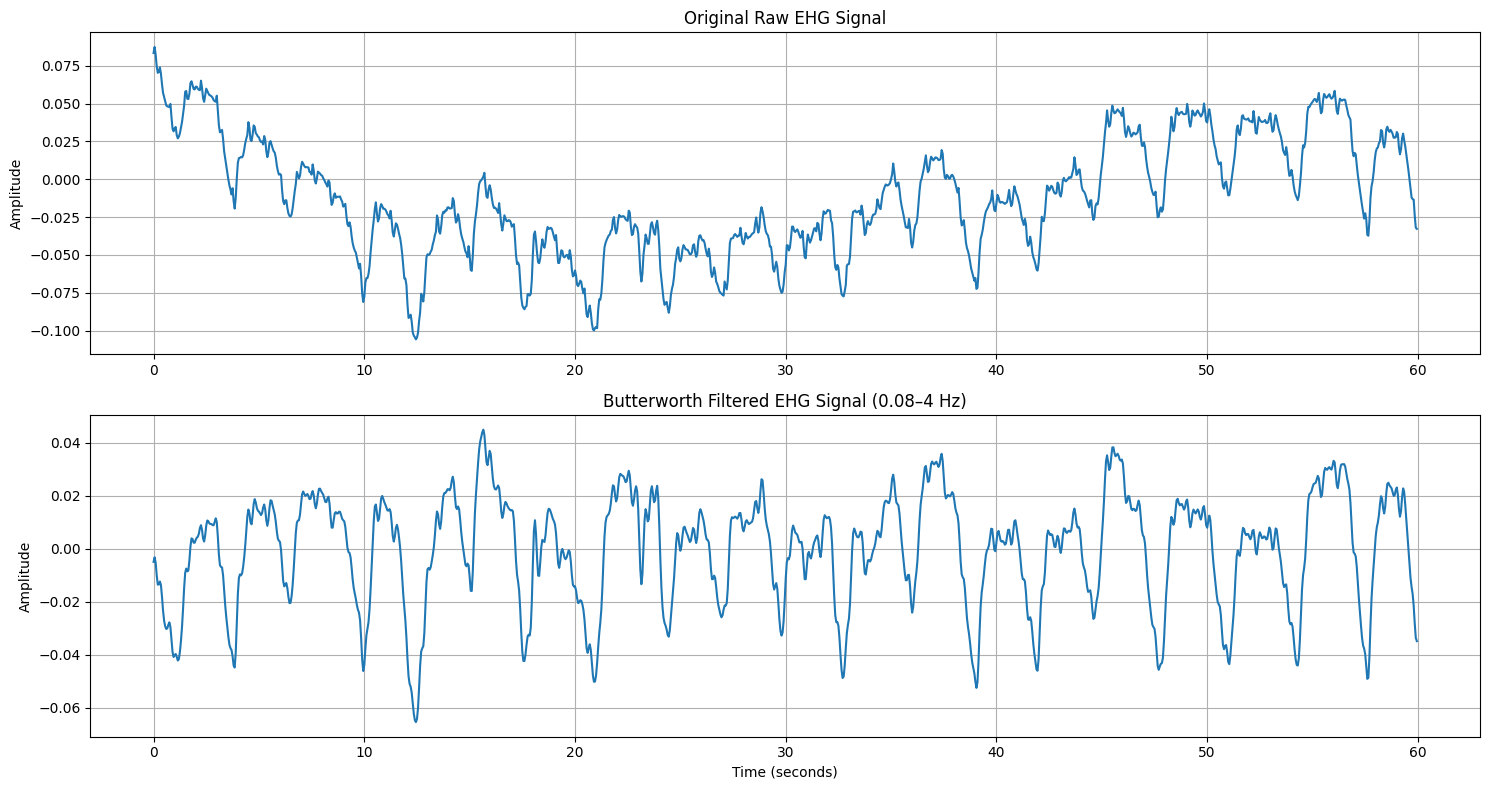

In [8]:

# Compare raw and filtered EHG signals

duration = 60
samples = duration * fs

time = np.arange(samples) / fs

plt.figure(figsize=(15, 8))

# Original signal
plt.subplot(2, 1, 1)

plt.plot(time, raw_signal[:samples])

plt.title("Original Raw EHG Signal")
plt.ylabel("Amplitude")
plt.grid(True)

# Filtered signal
plt.subplot(2, 1, 2)

plt.plot(time, filtered_signal[:samples])

plt.title("Butterworth Filtered EHG Signal (0.08–4 Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()
